In [22]:
from datasets import load_dataset

# ds = load_dataset("Suyogyart/np20ng")

In [23]:
ds = load_dataset("Suyogyart/np20ng")
print(ds)
df = ds["train"].to_pandas()   # use the split name that print(ds) shows
print(df.shape, df.columns.tolist())


DatasetDict({
    train: Dataset({
        features: ['source', 'category', 'heading', 'content'],
        num_rows: 231216
    })
})
(231216, 4) ['source', 'category', 'heading', 'content']


In [24]:
import os
print(os.getcwd())

from pathlib import Path
Path("../data/raw").mkdir(parents=True, exist_ok=True)

df.to_parquet("../data/raw/np20ng_raw.parquet")

c:\Tech\projects\nepali-nlp-study\notebooks


In [25]:
print(df.shape)
print(df.columns.tolist())
print(df["category"].value_counts())

(231216, 4)
['source', 'category', 'heading', 'content']
category
Politics         31021
Society          27802
Sports           24392
Economy          23653
Entertainment    22664
World            17431
Business         11645
Bank             10526
Health            9469
Crime             8173
Arts              7712
Technology        6427
Automobile        5152
Market            4373
Literature        4149
Opinion           3945
Lifestyle         3865
Education         3709
Tourism           3177
Employment        1931
Name: count, dtype: int64


In [26]:
print(df.dtypes)
print(df.isna().sum())
print(df.info())
empty = (df["content"].fillna("").str.strip() =="").sum()
print("empty content:", empty)
print(df.sample(3, random_state=1)[["category", "source", "heading"]])
print(df.sample(1, random_state=1)["content"].iloc[0][:500])

source      str
category    str
heading     str
content     str
dtype: object
source       0
category     0
heading      2
content     25
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 231216 entries, 0 to 231215
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   source    231216 non-null  str  
 1   category  231216 non-null  str  
 2   heading   231214 non-null  str  
 3   content   231191 non-null  str  
dtypes: str(4)
memory usage: 1.1 GB
None
empty content: 30
          category        source  \
24074   Technology  Onlinekhabar   
126664        Bank   Aarthiknews   
196588  Automobile      Setopati   

                                                  heading  
24074   एनसेलको मेरो प्लान अब साप्ताहिक प्याकमा, के छन...  
126664  साना किसान विकास लघुवित्तले गर्यो २६ दशमलव ३२ ...  
196588  होन्डाको नयाँ बाइक नेपाली बजारमा, कति पर्ला मू...  
एनसेलले आफ्ना प्रिपेड ग्राहकका लागि मेरो प्लान अन्तर्गत साप्ताहिक प्लान ल्याएक

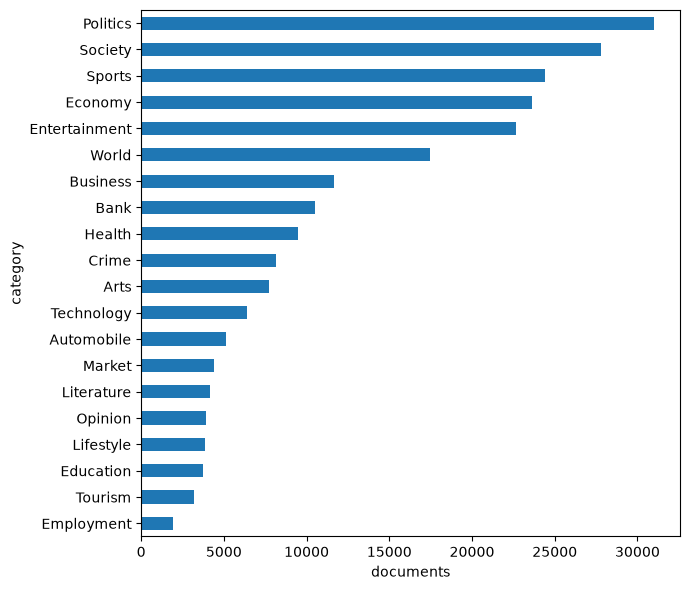

In [27]:
import matplotlib.pyplot as plt
counts = df["category"].value_counts()
counts.plot(kind="barh", figsize=(7, 6)).invert_yaxis()
plt.xlabel("documents"); plt.tight_layout()
plt.savefig("../results/figures/class_distribution.png", dpi=150)

In [28]:
import pandas as pd

print(df["source"].value_counts())
ct = pd.crosstab(df["category"], df["source"])
print(ct)
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1)) 

source
Nepalkhabar      69506
Onlinekhabar     66716
Ekantipur        29875
Aarthiknews      25965
Setopati         15541
Nagarik          11108
Gorkhapatra       5059
Crimenews         3921
Nepalipatra       1977
Educationpati     1548
Name: count, dtype: int64
source         Aarthiknews  Crimenews  Educationpati  Ekantipur  Gorkhapatra  \
category                                                                       
Arts                     0          0              0          0            0   
Automobile             900          0              0          0            0   
Bank                  7638          0              0          0            0   
Business              4706          0              0       3390            0   
Crime                    0       3921              0          0            0   
Economy               5247          0              0          0         1037   
Education                0          0           1548          0          806   
Employment       

In [29]:
df["category"].value_counts()
df["category"].nunique()
df["category"].unique()

<ArrowStringArray>
[    'Education',         'World',        'Sports',       'Society',
    'Technology',          'Bank',       'Economy',         'Crime',
        'Health',     'Lifestyle',        'Market',       'Opinion',
    'Employment',      'Politics',    'Automobile',          'Arts',
       'Tourism',    'Literature', 'Entertainment',      'Business']
Length: 20, dtype: str

In [30]:
print("largest class: ", counts.max())
print("smallest class: ", counts.min())
print("Imbalance ratio: ", counts.max()/counts.min())

largest class:  31021
smallest class:  1931
Imbalance ratio:  16.064733298808907


In [32]:
pd.set_option("display.max_colwidth", 300)

df[["category", "heading", "content"]].sample(
    5,
    random_state=42
)



,category,heading,content
35021,Health,२४ घण्टामा कोरोनाले बिपी प्रतिष्ठानमा तीन जनाको मृत्यु,"धरान, माघ ७ गते । धरानस्थित बिपी कोइराला स्वास्थ्य विज्ञान प्रतिष्ठानमा पछिल्लो २४ घण्टामा कोरोना सङ्क्रमणबाट तीन जनाको ज्यान गएको छ । गत माघ ६ गते भर्ना भएका लहान–१९ का ६२ वर्षीय पुरुषको उपचारको क्रममा शुक्रबार मृत्यु भएको प्रतिष्ठानले जनाएको छ । फोक्सोमा समस्या भएर उहाँलाई बिहीबार प्रतिष्ठानमा..."
22733,Technology,स्मार्टफोनपछि ल्यापटप र डेस्कटपमापनि फेसबुक लाइभ फिचर,क्यालिर्फोनिया–विश्वप्रसिद्ध सामाजिक संजाल फेसबुकले ल्यापटप र डेस्कटपमा पनि फेसबुक लाइभ फिचर ल्याउने भएको छ।\r\nफेसबुकले एक विज्ञप्ति जारी गर्दै हालसम्म एप्पल र एन्ड्रोइड स्माटएफोनमा मात्र उपलब्ध रहेको फेसबुक लाइभ फिचर ल्यापटप र डेस्कटपमासमेत सुरु गर्न लागेको जनाएको छ। फेसबुकले हाललाई उक्त फिच...
128445,Economy,आईएमई पे एपको टप–अपमा नयाँ क्यासब्याक अफर अद्यावधिक,आईएमई पेले मोबाइल रिचार्जमा नयाँ अफर अद्यावधिक गरिएको छ। आईएमई पे एपले दैनिक उपभोग्य सेवाहरूको भुक्तानीको साथै अन्य सम्पूर्ण किसिमको भुक्तानी तथा पैसाको लेनदेन सरल बनाउँदै आएको छ। यसै सेवामा थप प्रवर्द्धन गर्ने मुख्य उद्देश्यका साथ आईएमई पेले मोबाइल रिचार्जमा थप २ प्रतिशत क्यासब्याकको अफर ल्या...
158314,Health,भारतमा कोरोना संक्रमणबाट मर्नेको संख्या २१ सय नाघ्यो,भारत । भारतमा कोरोना संक्रमणका कारण मर्नेको संख्या २१ सय नाघेको छ । वल्ड्रोमिटरको तथ्याँकअनुसार आइतबार विहानसम्म भारतमा संक्रमणका कारण मर्नेको संख्या २१ सय १ पुगेको हो । त्यस्तै संक्रमितहरुको संख्या ६२ हजार ८ सय ८ पुगेको छ भने १९ हजार भन्दा बढि निको भएर फर्किसकेका छन् । \n
206400,Entertainment,आमिरको ‘लालसिंह चड्डा’मा शाहरुखको इन्ट्री!,बलिउडका सुपरस्टार अभिनेता आमिर खानको महत्वाकांक्षी फिल्म ‘लालसिंह चड्डा’मा अर्का सुपरस्टार शाहरुख खानको इन्ट्री भएको छ। भारतीय सञ्चारमाध्यका अनुसार आमिरको फिल्ममा शाहरुख पनि जोडिन पुगेका हुन्। यसको बारेमा औपचारिक घोषणा भने हुन बाँकी रहेको बताइएको छ। फिल्म लालसिंह चड्डामा शाहरुख छोटो तर महत्वपूर्...


In [33]:
df["text_length"] = df["content"].fillna("").str.len()

df["text_length"].describe()


count    231216.000000
mean       1764.981818
std        1921.064721
min           0.000000
25%         754.000000
50%        1153.000000
75%        2002.000000
max       56398.000000
Name: text_length, dtype: float64

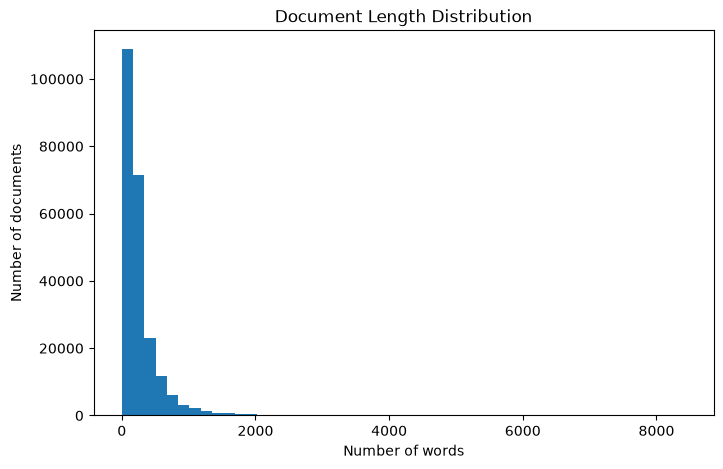

In [36]:
df["word_count"] = (
    df["content"]
    .fillna("")
    .str.split()
    .str.len()
)
plt.figure(figsize=(8, 5))

plt.hist(
    df["word_count"],
    bins=50
)

plt.xlabel("Number of words")
plt.ylabel("Number of documents")
plt.title("Document Length Distribution")

plt.show()

In [39]:

df.groupby("category")["word_count"].describe()
# df.groupby("category")["word_count"].mean().sort_values()


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Arts,7712.0,326.261281,426.651881,16.0,115.0,176.0,304.0,4309.0
Automobile,5152.0,254.472438,219.421948,31.0,132.0,192.0,291.0,3692.0
Bank,10526.0,227.563177,227.147067,10.0,112.0,163.0,251.0,7082.0
Business,11645.0,311.088879,261.568827,9.0,144.0,227.0,398.0,4101.0
Crime,8173.0,189.103634,253.279893,0.0,81.0,115.0,183.0,3522.0
Economy,23653.0,285.510083,268.480404,6.0,124.0,208.0,361.0,7233.0
Education,3709.0,399.751955,354.662290,20.0,190.0,312.0,490.0,5872.0
Employment,1931.0,315.283273,253.732571,26.0,145.0,238.0,405.0,2564.0
Entertainment,22664.0,225.513943,195.838693,1.0,121.0,163.0,246.0,2817.0


In [40]:
df.groupby("category")["word_count"].mean().sort_values()


category
Market            163.432884
Crime             189.103634
Society           195.132005
Entertainment     225.513943
Bank              227.563177
Sports            233.762176
World             234.516494
Politics          240.041166
Automobile        254.472438
Technology        265.802085
Economy           285.510083
Tourism           290.783444
Business          311.088879
Employment        315.283273
Arts              326.261281
Health            327.723308
Education         399.751955
Lifestyle         409.425873
Literature        542.712461
Opinion          1177.113815
Name: word_count, dtype: float64

In [41]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 58


In [42]:
print(
    "Duplicate contents:",
    df["content"].duplicated().sum()
)

Duplicate contents: 251


In [45]:
duplicates = df[
    df["content"].duplicated(keep=False)
].sort_values("content")

duplicates[["category", "content"]].head(10)
# print(duplicates)

,category,content
35946,Lifestyle,"- अदुवामा पाइने भिटामिन, खनिज र एमिनो एसिडले रक्तसञ्चार राम्रो बनाउँछ । साथै, हृदयाघात र मुटुरोगीका लागि फाइदाजनक हुन्छ । - एन्टिअक्सिडेन्टको मात्रा बढ्छ । फलस्वरूप शरीरमा रोगप्रतिरोधात्मक क्षमता वृद्धि हुन्छ । -दैनिक अदुवा–चिया पिउँदा तनाव कम हुन्छ । साथै, चिया र अदुवाको मिश्रणबाट बन्ने रस..."
36887,Lifestyle,"- अदुवामा पाइने भिटामिन, खनिज र एमिनो एसिडले रक्तसञ्चार राम्रो बनाउँछ । साथै, हृदयाघात र मुटुरोगीका लागि फाइदाजनक हुन्छ । - एन्टिअक्सिडेन्टको मात्रा बढ्छ । फलस्वरूप शरीरमा रोगप्रतिरोधात्मक क्षमता वृद्धि हुन्छ । -दैनिक अदुवा–चिया पिउँदा तनाव कम हुन्छ । साथै, चिया र अदुवाको मिश्रणबाट बन्ने रस..."
36148,Lifestyle,"काठमाडौं । तोरी, नरिवल वा सस्र्यूंको तेल तताएर हलुका मसाज गर्ने । जरासम्म पुग्ने गरी मसाज गरेर स्याम्पुले कपाल पखाल्ने । –ग्रिन टीसहितको पानी मनतातो बनाएर कपालमा लगाई केही बेरमा धुने । ग्रिन टीमा एन्टिअक्सिडेन्ट तत्व हुने भएकाले कपाल झर्नबाट रोक्नुका साथै कपाल छिटो बढ्छ । –टाउकोमा दिनहुँ..."
36938,Lifestyle,"काठमाडौं । तोरी, नरिवल वा सस्र्यूंको तेल तताएर हलुका मसाज गर्ने । जरासम्म पुग्ने गरी मसाज गरेर स्याम्पुले कपाल पखाल्ने । –ग्रिन टीसहितको पानी मनतातो बनाएर कपालमा लगाई केही बेरमा धुने । ग्रिन टीमा एन्टिअक्सिडेन्ट तत्व हुने भएकाले कपाल झर्नबाट रोक्नुका साथै कपाल छिटो बढ्छ । –टाउकोमा दिनहुँ..."
35646,Lifestyle,एजेन्सी
35665,Lifestyle,एजेन्सी
35688,Lifestyle,एजेन्सी
35712,Lifestyle,एजेन्सी
35735,Lifestyle,एजेन्सी
35802,Lifestyle,एजेन्सी


In [49]:
duplicate_groups = (
    df[df["content"].duplicated(keep=False)]
    .groupby("content")["category"]
    .nunique()
)

duplicate_groups.value_counts()

category
1    141
2      5
Name: count, dtype: int64

In [47]:
# create a clean dataframe dont mutate original data

data = df[["category", "content"]].copy()
data = data.dropna(subset=["category", "content"])
data = data[
    data["content"].str.strip() != ""
]

print(data.shape)
print(data.isna().sum)



(231186, 2)
<bound method DataFrame.sum of         category  content
0          False    False
1          False    False
2          False    False
3          False    False
4          False    False
...          ...      ...
231211     False    False
231212     False    False
231213     False    False
231214     False    False
231215     False    False

[231186 rows x 2 columns]>


In [51]:
from sklearn.model_selection import train_test_split
X=data["content"]
y=data["category"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X,y,test_size = 0.2, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size = 0.5, random_state=42, stratify=y_temp
)
 

In [58]:
#TF-IDF begins
#first baseline

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
X_val_tfidf = tfidf.transform(X_val)

print(X_train_tfidf.shape)




(184948, 74256)


In [59]:
model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_tfidf,
    y_train
)

y_val_pred = model.predict(X_val_tfidf)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(
    y_val, y_val_pred 
)
print(accuracy)

from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_val_pred
    )
)

0.7348933777412517
               precision    recall  f1-score   support

         Arts       0.62      0.48      0.54       771
   Automobile       0.77      0.74      0.75       515
         Bank       0.72      0.78      0.75      1053
     Business       0.54      0.38      0.44      1164
        Crime       0.75      0.76      0.75       818
      Economy       0.55      0.57      0.56      2365
    Education       0.78      0.75      0.76       371
   Employment       0.60      0.54      0.57       193
Entertainment       0.81      0.87      0.84      2266
       Health       0.71      0.62      0.66       947
    Lifestyle       0.75      0.74      0.75       386
   Literature       0.66      0.62      0.64       415
       Market       0.67      0.53      0.60       438
      Opinion       0.82      0.75      0.78       394
     Politics       0.83      0.87      0.85      3102
      Society       0.64      0.69      0.66      2780
       Sports       0.96      0.96      0.96 

<Figure size 1000x1000 with 0 Axes>

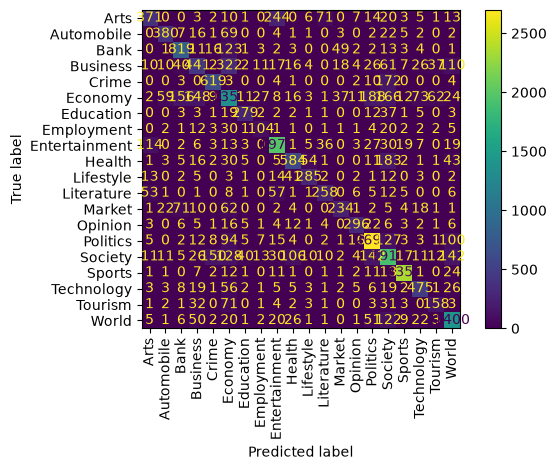

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(10, 10))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    xticks_rotation=90
)

plt.tight_layout()
plt.show()

In [63]:
def run_tfidf_experiment(ngram_range):
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range
    )

    X_train_vec = vectorizer.fit_transform(X_train)
    X_val_vec = vectorizer.transform(X_val)

    model = LogisticRegression(
        max_iter=1000
    )

    model.fit(X_train_vec, y_train)

    predictions = model.predict(X_val_vec)

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    report = classification_report(
        y_val,
        predictions,
        output_dict=True
    )

    return {
        "accuracy": accuracy,
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
        "features": X_train_vec.shape[1]
    }
results = {}

results["unigram"] = run_tfidf_experiment((1, 1))
results["unigram_bigram"] = run_tfidf_experiment((1, 2))
# results["unigram_trigram"] = run_tfidf_experiment((1, 3))

results

{'unigram': {'accuracy': 0.7348933777412517,
  'macro_f1': 0.6950122585358939,
  'weighted_f1': 0.7310049041534247,
  'features': 74256},
 'unigram_bigram': {'accuracy': 0.762532981530343,
  'macro_f1': 0.7184403356728789,
  'weighted_f1': 0.758802459026867,
  'features': 2511191}}

In [72]:
vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2
)

X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train_vec, y_train)

predictions = model.predict(X_val_vec)

accuracy = accuracy_score(
    y_val,
    predictions
)

report = classification_report(
    y_val,
    predictions,
    output_dict=True
)

report 

{'Arts': {'precision': 0.6949740034662045,
  'recall': 0.5201037613488976,
  'f1-score': 0.5949554896142433,
  'support': 771.0},
 'Automobile': {'precision': 0.7991803278688525,
  'recall': 0.7572815533980582,
  'f1-score': 0.7776669990029911,
  'support': 515.0},
 'Bank': {'precision': 0.7618198037466548,
  'recall': 0.8110161443494777,
  'f1-score': 0.7856485740570377,
  'support': 1053.0},
 'Business': {'precision': 0.5966785290628707,
  'recall': 0.4321305841924399,
  'f1-score': 0.5012456402590931,
  'support': 1164.0},
 'Crime': {'precision': 0.7855392156862745,
  'recall': 0.7836185819070904,
  'f1-score': 0.784577723378213,
  'support': 818.0},
 'Economy': {'precision': 0.5904,
  'recall': 0.6241014799154334,
  'f1-score': 0.6067831449126413,
  'support': 2365.0},
 'Education': {'precision': 0.8017492711370262,
  'recall': 0.7412398921832885,
  'f1-score': 0.7703081232492998,
  'support': 371.0},
 'Employment': {'precision': 0.6554054054054054,
  'recall': 0.5025906735751295,


In [73]:
report

{'Arts': {'precision': 0.6949740034662045,
  'recall': 0.5201037613488976,
  'f1-score': 0.5949554896142433,
  'support': 771.0},
 'Automobile': {'precision': 0.7991803278688525,
  'recall': 0.7572815533980582,
  'f1-score': 0.7776669990029911,
  'support': 515.0},
 'Bank': {'precision': 0.7618198037466548,
  'recall': 0.8110161443494777,
  'f1-score': 0.7856485740570377,
  'support': 1053.0},
 'Business': {'precision': 0.5966785290628707,
  'recall': 0.4321305841924399,
  'f1-score': 0.5012456402590931,
  'support': 1164.0},
 'Crime': {'precision': 0.7855392156862745,
  'recall': 0.7836185819070904,
  'f1-score': 0.784577723378213,
  'support': 818.0},
 'Economy': {'precision': 0.5904,
  'recall': 0.6241014799154334,
  'f1-score': 0.6067831449126413,
  'support': 2365.0},
 'Education': {'precision': 0.8017492711370262,
  'recall': 0.7412398921832885,
  'f1-score': 0.7703081232492998,
  'support': 371.0},
 'Employment': {'precision': 0.6554054054054054,
  'recall': 0.5025906735751295,


In [65]:
def run_tfidf_experiment(ngram_range, c):
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range
    )

    X_train_vec = vectorizer.fit_transform(X_train)
    X_val_vec = vectorizer.transform(X_val)

    model = LogisticRegression(
        C=c,
        max_iter=1000
    )

    model.fit(X_train_vec, y_train)

    predictions = model.predict(X_val_vec)

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    report = classification_report(
        y_val,
        predictions,
        output_dict=True
    )

    return {
        "accuracy": accuracy,
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
        "features": X_train_vec.shape[1]
    }
results = {}

results["unigram_0.1"] = run_tfidf_experiment((1, 1),0.1)
results["unigram_1"] = run_tfidf_experiment((1, 1),1)
results["unigram_10"] = run_tfidf_experiment((1, 1),10)
# results["unigram_trigram"] = run_tfidf_experiment((1, 3))

results

{'unigram_0.1': {'accuracy': 0.6968727021064925,
  'macro_f1': 0.632791114145369,
  'weighted_f1': 0.6885637066525403,
  'features': 74256},
 'unigram_1': {'accuracy': 0.7348933777412517,
  'macro_f1': 0.6950122585358939,
  'weighted_f1': 0.7310049041534247,
  'features': 74256},
 'unigram_10': {'accuracy': 0.7383969894891648,
  'macro_f1': 0.7017497720388468,
  'weighted_f1': 0.7362439204571316,
  'features': 74256}}

In [70]:
vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=6
)

X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train_vec, y_train)

predictions = model.predict(X_val_vec)

accuracy = accuracy_score(
    y_val,
    predictions
)

report = classification_report(
    y_val,
    predictions,
    output_dict=True
)



In [71]:
report

{'Arts': {'precision': 0.7015437392795884,
  'recall': 0.5304798962386511,
  'f1-score': 0.604135893648449,
  'support': 771.0},
 'Automobile': {'precision': 0.8004115226337448,
  'recall': 0.7553398058252427,
  'f1-score': 0.7772227772227772,
  'support': 515.0},
 'Bank': {'precision': 0.7618198037466548,
  'recall': 0.8110161443494777,
  'f1-score': 0.7856485740570377,
  'support': 1053.0},
 'Business': {'precision': 0.6025791324736225,
  'recall': 0.4415807560137457,
  'f1-score': 0.5096678235002479,
  'support': 1164.0},
 'Crime': {'precision': 0.7920792079207921,
  'recall': 0.78239608801956,
  'f1-score': 0.7872078720787208,
  'support': 818.0},
 'Economy': {'precision': 0.5939637826961771,
  'recall': 0.6241014799154334,
  'f1-score': 0.608659793814433,
  'support': 2365.0},
 'Education': {'precision': 0.8011695906432749,
  'recall': 0.738544474393531,
  'f1-score': 0.7685834502103787,
  'support': 371.0},
 'Employment': {'precision': 0.6554054054054054,
  'recall': 0.5025906735